# PNRR project-title classification: MLP versus CNN

Executed analysis of real training runs on the workspace data. MLP achieved the highest test macro-F1 (0.389). The stronger neural model was MLP (0.389). These values measure agreement with inherited programme themes on unseen measure groups.

This notebook loads saved experiment outputs so opening or executing it does not silently retrain or change test selections. Complete implementations are in `src/prepare.py` and `src/train.py`. The original proposal is preserved.

In [1]:
from pathlib import Path
import json, sys, inspect
import pandas as pd
from IPython.display import display, Image, Markdown, Code
ROOT = Path.cwd()
assert (ROOT / 'data/progetti.csv').exists(), 'Run from the project root'
sys.path.insert(0, str(ROOT / 'src'))
from prepare import clean_title, prepare
from train import TitleMLP, TitleCNN, fit_neural
A = ROOT / 'artifacts'
r = json.loads((A / 'results.json').read_text())
audit = json.loads((A / 'data_audit.json').read_text())
display(pd.Series(r['environment'], name='Training environment'))

python                                   3.13.5
torch                                    2.12.0
numpy                                     2.1.3
pandas                                    2.2.3
sklearn                                   1.6.1
device                                      cpu
threads                                       4
platform    macOS-26.5.1-arm64-arm-64bit-Mach-O
Name: Training environment, dtype: object

## 1. Dataset, inherited labels, and cleaning

Join projects → measures → root themes. Use titles only; remove label-revealing identifiers. Conflicting titles, unmatched measures, and unsupported classes are excluded. Exact title duplicates are collapsed. Labels remain provisional programme categories.

In [2]:
display(pd.Series({k: audit[k] for k in ['raw_projects', 'unmatched_measure_rows', 'titles_under_three_tokens', 'conflicting_title_rows_removed', 'duplicate_clean_titles_removed', 'retained_unique_titles']}))
display(pd.DataFrame(audit['class_support_before_filter']))
display(Code(inspect.getsource(clean_title), language='python'))
print(clean_title('M1C1I1.04.05 SERVIZI DIGITALI PER LA COMUNITÀ E71F22003570006'))

raw_projects                      298338
unmatched_measure_rows               406
titles_under_three_tokens              2
conflicting_title_rows_removed      2905
duplicate_clean_titles_removed    128444
retained_unique_titles            166521
dtype: int64

,label,titles,independent_groups
0,Cultura e turismo,9011,9
1,Digitalizzazione,38096,9
2,Giustizia,6,2
3,Impresa e lavoro,41018,16
4,Inclusione sociale,6918,6
5,Infrastrutture,3075,17
6,Pubblica amministrazione,54,3
7,Salute,9362,6
8,"Scuola, università e ricerca",50828,19
9,Transizione ecologica,8213,30


def clean_title(value):
    text = unicodedata.normalize('NFKC', str(value)).lower()
    # Strip embedded mission/component/investment codes before punctuation removal.
    text = re.sub(r'\bm\s*\d+\s*c\s*\d+(?:\s*i\s*[\d.]+)?', ' ', text)
    # CUPs, local identifiers, dates, and numeric references are not language features.
    text = re.sub(r'\b\w*\d\w*\b', ' ', text)
    text = re.sub(r'[^a-zàèéìòóù\s]', ' ', text)
    return ' '.join(text.split())

servizi digitali per la comunità


## 2. Isolated groups and train-only feature fitting

Connected root measures, CUPs, and exact normalized titles cannot cross partitions. Split selection uses labels/group sizes, never model scores. Training/validation are sampled within those partitions; the test partition is complete. Digitalisation is dominated by one large group, so exact stratification is infeasible.

In [3]:
display(pd.DataFrame({s: d['class_counts'] for s, d in r['diagnostics'].items()}))
display(pd.DataFrame([{"split": s, **{k: v for k, v in d.items() if k != 'class_counts'}} for s, d in r['diagnostics'].items()]))
print('Verified isolation:', audit['leakage_assertions_passed'])
display(Code(inspect.getsource(prepare), language='python'))

,train,validation,test
Digitalizzazione,7540,192,278
"Scuola, università e ricerca",7411,2543,5714
Impresa e lavoro,4976,2369,8494
Cultura e turismo,1069,639,1585
Transizione ecologica,920,714,1267
Salute,887,874,2042
Inclusione sociale,818,542,1059
Infrastrutture,379,127,780


,split,rows,groups,oov_token_rate,truncated_title_rate
0,train,24000,53,0.034118,0.0
1,validation,8000,20,0.115414,0.0
2,test,21219,24,0.157366,0.0


Verified isolation: ['group', 'family', 'misura_id', 'cup', 'text']


def prepare(out=ROOT / 'artifacts', seed=42):
    out.mkdir(exist_ok=True, parents=True)
    audit = {'seed': seed, 'source_sha256': {},
             'minimum_class_titles': 500, 'minimum_class_groups': 6}
    for name in ['progetti', 'misure', 'temi']:
        path = ROOT / 'data' / f'{name}.csv'
        audit['source_sha256'][path.name] = hashlib.sha256(path.read_bytes()).hexdigest()
    p = pd.read_csv(ROOT / 'data/progetti.csv', usecols=['progetto_id', 'titolo', 'cup', 'misura_id'])
    m = pd.read_csv(ROOT / 'data/misure.csv')
    t = pd.read_csv(ROOT / 'data/temi.csv')
    audit['raw_projects'] = len(p)
    audit['missing_titles'] = int(p.titolo.isna().sum())
    audit['duplicate_project_ids'] = int(p.progetto_id.duplicated().sum())
    if p.progetto_id.duplicated().any():
        raise ValueError('Resolve duplicate project IDs before proceeding')
    p = p.merge(m[['id', 'tema']], left_on='misura_id', right_on='id', how='left', validate='many_to_one')
    audit['unmatched_measure_ids'] = sorted(p.loc[p.tema.isna(), 'misura_id'].unique().tolist())
    audit['unmatched_measure_rows'] = int(p.tema.isna().sum())
    p = p.dropna(subset=['tema', 'titolo']).copy()
    theme_parents = t.set_index('id').parent_id.to_dict()
    measure_parents = m.set_index('id').madre_id.to_dict()
    names = t.set_index('id').descrizione.to_dict()
    p['label'] = p.tema.map(lambda x: names[ancestor(int(x), theme_parents)])
    p['family'] = p.misura_id.map(lambda x: ancestor(int(x), measure_parents))
    p['text'] = p.titolo.map(clean_title)
    short = p.text.str.split().str.len() < 3
    audit['titles_under_three_tokens'] = int(short.sum())
    p = p.loc[~short].copy()
    conflict = p.groupby('text').label.nunique()
    conflict = set(conflict[conflict > 1].index)
    audit['conflicting_title_strings'] = len(conflict)
    audit['conflicting_title_rows_removed'] = int(p.text.isin(conflict).sum())
    p = p.loc[~p.text.isin(conflict)].copy()
    # Union measure families when any remaining title or CUP links them.
    parents = {int(x): int(x) for x in p.family.unique()}

    def find(x):
        while parents[x] != x:
            parents[x] = parents[parents[x]]
            x = parents[x]
        return x

    def union(a, b):
        a, b = find(a), find(b)
        if a != b:
            parents[max(a, b)] = min(a, b)

    for col in ['text', 'cup']:
        first = {}
        for key, family in zip(p[col], p.family):
            if pd.isna(key) or not str(key).strip():
                continue
            if key in first:
                union(first[key], int(family))
            else:
                first[key] = int(family)
    p['group'] = p.family.map(find)
    audit['duplicate_clean_titles_removed'] = int(p.text.duplicated().sum())
    p = p.drop_duplicates('text').copy()
    support = p.groupby('label').agg(titles=('text', 'size'), independent_groups=('group', 'nunique'))
    audit['class_support_before_filter'] = support.reset_index().to_dict('records')
    eligible = support.index[(support.titles >= 500) & (support.independent_groups >= 6)]
    audit['excluded_classes'] = support.loc[~support.index.isin(eligible)].reset_index().to_dict('records')
    p = p[p.label.isin(eligible)].copy()
    if len(eligible) < 2:
        raise ValueError('Insufficient independent class groups for a defensible split')
    # Search labels/group sizes only, never model performance, for a feasible 60/20/20 split.
    labels = sorted(eligible)
    table = pd.crosstab(p.group, p.label).reindex(columns=labels, fill_value=0)
    counts = table.to_numpy()
    target = np.array([.6, .2, .2])
    rng = np.random.default_rng(seed)
    if np.any((counts > 0).sum(axis=1) != 1):
        raise ValueError('Mixed-label components require a joint group-split optimizer')
    assignment = np.zeros(len(table), dtype=int)
    class_errors = []
    for column in range(len(labels)):
        indices = np.flatnonzero(counts[:, column])
        n_holdout = max(2, round(len(ind

## 3. Two different deep learning architectures

**MLP:** TF–IDF unigrams/bigrams, two nonlinear hidden layers.

**CNN:** learned token embeddings, parallel convolutions over ordered tokens, masked global pooling, and a nonlinear dense head. ReLU and 8 output logits are used in both.

In [4]:
display(Code(inspect.getsource(TitleMLP), language='python'))
display(Code(inspect.getsource(TitleCNN), language='python'))
print('Selected models:', r['selected'])
print(TitleMLP(r['tfidf_features'], len(r['classes'])))
print(TitleCNN(r['vocab_size'], len(r['classes'])))

class TitleMLP(nn.Module):
    """Two hidden layers learn nonlinear combinations of TF-IDF features."""
    def __init__(self, n_features, n_classes, dropout=.4):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_features, 128), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(64, n_classes))

    def forward(self, x):
        return self.net(x)

class TitleCNN(nn.Module):
    """Learn embeddings and local 3/5-token patterns; masked global max pooling."""
    def __init__(self, vocab_size, n_classes, dropout=.4):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, 64, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(64, 64, k, padding=k // 2) for k in (3, 5)])
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(128, 64), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(64, n_classes))

    def forward(self, x):
        valid = (x != 0).unsqueeze(1)
        emb = self.embedding(x).transpose(1, 2)
        pooled = [torch.relu(conv(emb)).masked_fill(~valid, -1e4).amax(dim=2) for conv in self.convs]
        return self.head(torch.cat(pooled, dim=1))

Selected models: {'MLP': 'mlp_regularized', 'CNN': 'cnn_plain'}
TitleMLP(
  (net): Sequential(
    (0): Linear(in_features=6000, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.4, inplace=False)
    (6): Linear(in_features=64, out_features=8, bias=True)
  )
)
TitleCNN(
  (embedding): Embedding(12000, 64, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  )
  (head): Sequential(
    (0): Dropout(p=0.4, inplace=False)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=64, out_features=8, bias=True)
  )
)


## 4. Training, regularization, and tuning

All runs use AdamW, class-weighted cross-entropy, batch size 256, gradient clipping, a learning-rate scheduler, and early stopping on validation macro-F1. Compare no dropout/decay with dropout 0.4 plus decay 0.0001. This tests their combined effect. Restore the best checkpoint and freeze choices before testing. Logistic regression is also tuned on validation only.

In [5]:
display(Code(inspect.getsource(fit_neural), language='python'))
runs = pd.DataFrame([{"run": name, 'best_val_f1': v['validation']['macro_f1'], 'best_epoch': v['best_epoch'], 'epochs_run': v['epochs_run'], 'seconds': v['seconds'], 'parameters': v['parameters'], 'dropout': v['dropout'], 'weight_decay': v['weight_decay']} for name, v in r['runs'].items()])
display(runs)
display(pd.DataFrame(r['baseline_tuning']))

def fit_neural(name, model, xtrain, ytrain, xval, yval, weights, cfg, monitor_idx):
    seed_all()
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=.5, patience=1)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32))
    ytensor = torch.tensor(ytrain, dtype=torch.long)
    rng = np.random.default_rng(SEED)
    history, best, best_epoch, stale = [], -1., 0, 0
    start = time.perf_counter()
    for epoch in range(1, cfg['max_epochs'] + 1):
        epoch_start = time.perf_counter()
        model.train()
        order = rng.permutation(len(ytrain))
        optimization_loss = 0.
        lr = optimizer.param_groups[0]['lr']
        for offset in range(0, len(order), cfg['batch_size']):
            idx = order[offset:offset + cfg['batch_size']]
            optimizer.zero_grad(set_to_none=True)
            logits = model(batch_tensor(xtrain, idx))
            loss = criterion(logits, ytensor[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimizer.step()
            optimization_loss += loss.item() * len(idx)
        train_metrics = scores(ytrain[monitor_idx], predict(model, xtrain[monitor_idx]))
        val_metrics = scores(yval, predict(model, xval))
        row = {'epoch': epoch, 'lr': lr, 'optimization_loss': optimization_loss / len(ytrain),
               **{'train_' + k: v for k, v in train_metrics.items()},
               **{'val_' + k: v for k, v in val_metrics.items()},
               'seconds': time.perf_counter() - epoch_start}
        history.append(row)
        pd.DataFrame(history).to_csv(OUT / f'{name}_history.csv', index=False)
        print(f"{name:18} epoch={epoch:02} train_loss={row['train_loss']:.4f} "
              f"val_loss={row['val_loss']:.4f} val_acc={row['val_accuracy']:.4f} "
              f"val_F1={row['val_macro_f1']:.4f} lr={lr:.5f} seconds={row['seconds']:.1f}", flush=True)
        if val_metrics['macro_f1'] > best + 1e-4:
            best, best_epoch, stale = val_metrics['macro_f1'], epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            stale += 1
        scheduler.step(val_metrics['macro_f1'])
        if stale >= cfg['patience']:
            break
    model.load_state_dict(best_state)
    torch.save({'state_dict': best_state, 'config': cfg, 'best_epoch': best_epoch}, OUT / f'{name}.pt')
    result = {'name': name, **cfg, 'best_epoch': best_epoch, 'epochs_run': len(history),
              'seconds': time.perf_counter() - start,
              'parameters': sum(p.numel() for p in model.parameters()),
              'validation': scores(yval, predict(model, xval)),
              'last_epoch_validation_f1': history[-1]['val_macro_f1'],
              'lr_reductions': sum(history[i]['lr'] < history[i - 1]['lr'] for i in range(1, len(history)))}
    return model, result

,run,best_val_f1,best_epoch,epochs_run,seconds,parameters,dropout,weight_decay
0,mlp_plain,0.425374,4,7,18.475455,776904,0.0,0.0000
1,mlp_regularized,0.441476,4,7,28.048480,776904,0.4,0.0001
2,cnn_plain,0.395286,11,14,679.163997,809672,0.0,0.0000
3,cnn_regularized,0.382171,11,14,409.645796,809672,0.4,0.0001


,C,validation
0,0.5,"{'accuracy': 0.31775, 'macro_f1': 0.3493900398..."
1,2.0,"{'accuracy': 0.365875, 'macro_f1': 0.381955678..."


In [6]:
# Reproduction command, intentionally not run when browsing saved results:
# !{sys.executable} src/train.py --prepare --epochs 14 --train-limit 24000 --validation-limit 8000
# Then rebuild this notebook and the report:
# !{sys.executable} src/build_deliverables.py

## 5. Training process over time

Training metrics are evaluated on the same 3,000-title monitoring subset with dropout off. Validation uses 8,000 titles. Plotted losses are unweighted evaluation loss; optimization loss in the CSVs is weighted training loss. The regularization ablation and train–validation gap are visible below.

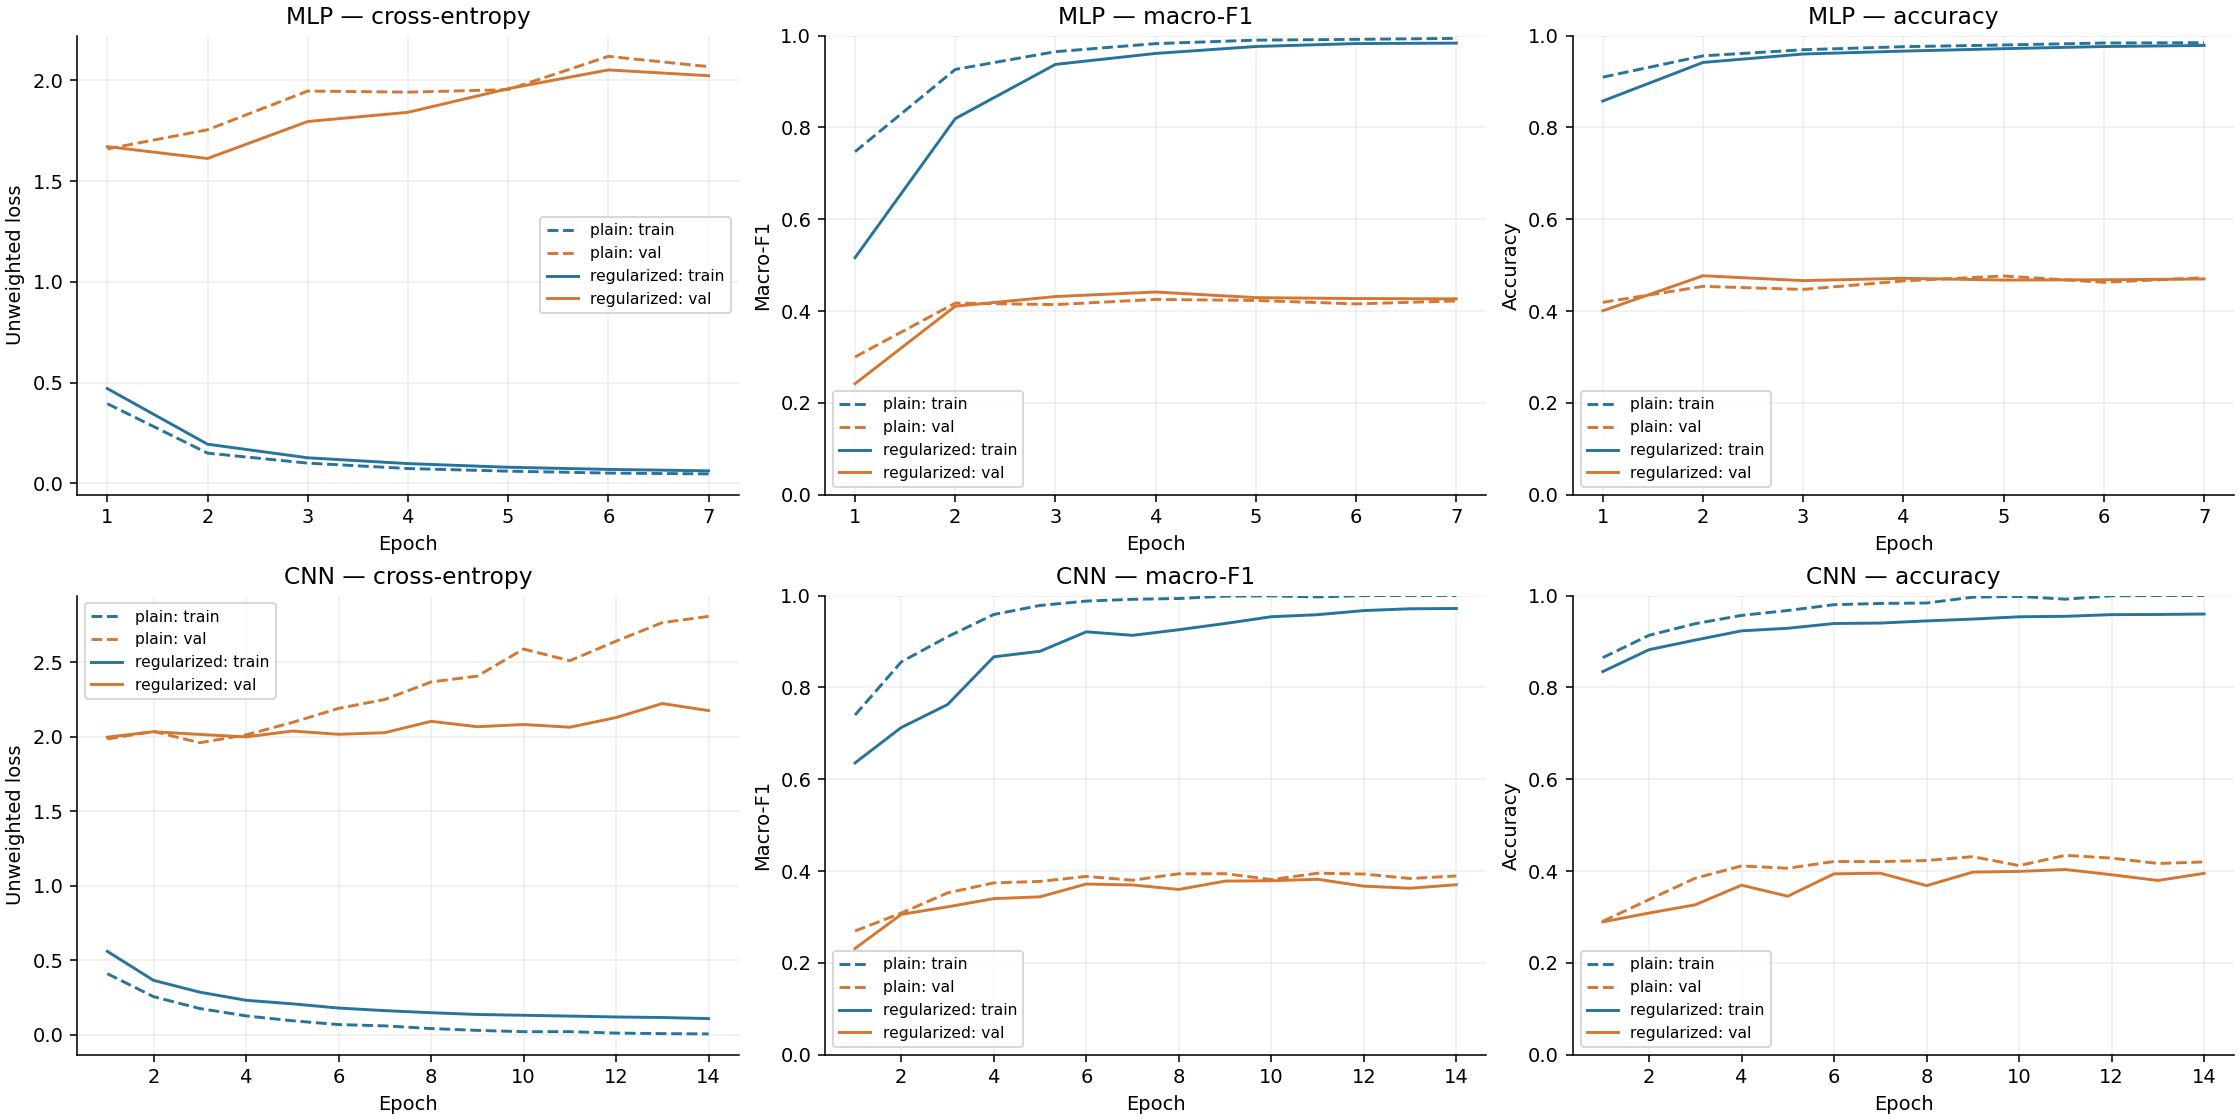

mlp_plain


,epoch,lr,optimization_loss,train_accuracy,train_macro_f1,train_loss,val_accuracy,val_macro_f1,val_loss,seconds
0,1,0.0010,1.4070,0.9093,0.7470,0.3950,0.4190,0.3001,1.6594,2.0121
1,2,0.0010,0.3665,0.9557,0.9261,0.1494,0.4538,0.4174,1.7546,2.7475
2,3,0.0010,0.1640,0.9690,0.9648,0.0998,0.4471,0.4141,1.9468,3.1979
3,4,0.0010,0.1054,0.9757,0.9823,0.0730,0.4656,0.4254,1.9414,2.7643
4,5,0.0010,0.0778,0.9793,0.9899,0.0599,0.4764,0.4231,1.9538,1.3195
5,6,0.0010,0.0609,0.9837,0.9916,0.0504,0.4626,0.4156,2.1190,3.4566
6,7,0.0005,0.0484,0.9843,0.9937,0.0463,0.4726,0.4220,2.0681,2.7899


mlp_regularized


,epoch,lr,optimization_loss,train_accuracy,train_macro_f1,train_loss,val_accuracy,val_macro_f1,val_loss,seconds
0,1,0.0010,1.4807,0.8573,0.5163,0.4701,0.4006,0.2418,1.6709,4.0698
1,2,0.0010,0.5777,0.9413,0.8190,0.1938,0.4769,0.4105,1.6120,4.6587
2,3,0.0010,0.2934,0.9597,0.9371,0.1263,0.4662,0.4316,1.7957,2.7014
3,4,0.0010,0.2001,0.9660,0.9609,0.0975,0.4714,0.4415,1.8412,1.3953
4,5,0.0010,0.1513,0.9713,0.9761,0.0793,0.4675,0.4293,1.9587,2.2712
5,6,0.0010,0.1238,0.9760,0.9824,0.0687,0.4681,0.4273,2.0517,7.3422
6,7,0.0005,0.1052,0.9783,0.9834,0.0615,0.4699,0.4266,2.0230,5.4593


cnn_plain


,epoch,lr,optimization_loss,train_accuracy,train_macro_f1,train_loss,val_accuracy,val_macro_f1,val_loss,seconds
0,1,0.0010,1.0601,0.8647,0.7397,0.4097,0.2908,0.2696,1.9848,72.7014
1,2,0.0010,0.4447,0.9133,0.8554,0.2551,0.3379,0.3085,2.0355,31.6754
2,3,0.0010,0.2845,0.9387,0.9102,0.1756,0.3845,0.3524,1.9597,38.3486
3,4,0.0010,0.1921,0.9567,0.9586,0.1262,0.4111,0.3744,2.0123,36.5756
4,5,0.0010,0.1339,0.9673,0.9784,0.0935,0.4061,0.3774,2.0958,34.8554
5,6,0.0010,0.0923,0.9800,0.9879,0.0679,0.4209,0.3883,2.1902,32.2195
6,7,0.0010,0.0642,0.9827,0.9918,0.0592,0.4205,0.3801,2.2501,30.5266
7,8,0.0010,0.0499,0.9837,0.9934,0.0412,0.4230,0.3941,2.3675,42.6613
8,9,0.0010,0.0366,0.9963,0.9985,0.0288,0.4314,0.3943,2.4071,61.2829
9,10,0.0010,0.0258,0.9980,0.9992,0.0201,0.4119,0.3815,2.5885,97.5400


cnn_regularized


,epoch,lr,optimization_loss,train_accuracy,train_macro_f1,train_loss,val_accuracy,val_macro_f1,val_loss,seconds
0,1,0.0010,1.3556,0.8343,0.6355,0.5595,0.2894,0.2315,1.9970,34.7741
1,2,0.0010,0.7938,0.8820,0.7126,0.3648,0.3086,0.3057,2.0336,25.6000
2,3,0.0010,0.6142,0.9030,0.7625,0.2853,0.3266,0.3221,2.0153,24.8447
3,4,0.0010,0.4918,0.9230,0.8665,0.2310,0.3692,0.3400,1.9988,24.6453
4,5,0.0010,0.4286,0.9287,0.8786,0.2071,0.3452,0.3439,2.0382,24.2199
5,6,0.0010,0.3736,0.9390,0.9209,0.1788,0.3940,0.3718,2.0163,24.9641
6,7,0.0010,0.3311,0.9400,0.9133,0.1614,0.3954,0.3697,2.0272,25.7577
7,8,0.0010,0.3017,0.9447,0.9254,0.1475,0.3682,0.3600,2.1034,43.0451
8,9,0.0005,0.2724,0.9487,0.9390,0.1357,0.3978,0.3782,2.0671,49.3031
9,10,0.0005,0.2496,0.9537,0.9538,0.1302,0.3992,0.3789,2.0822,29.9565


In [7]:
display(Image(filename=str(A / 'training_curves.png')))
for name in r['runs']:
    print(name)
    display(pd.read_csv(A / f'{name}_history.csv').round(4))

## 6. Held-out test results and class-level errors

All test rows are evaluated only after selection. Macro-F1 weighs categories equally; accuracy weighs titles. Scores estimate inherited-label agreement for unseen measure groups.

,accuracy,macro_f1,loss
Majority,0.0131,0.0032,NaN
Logistic,0.4214,0.3805,1.4881
MLP,0.4435,0.3890,1.6524
CNN,0.4179,0.2878,2.2585


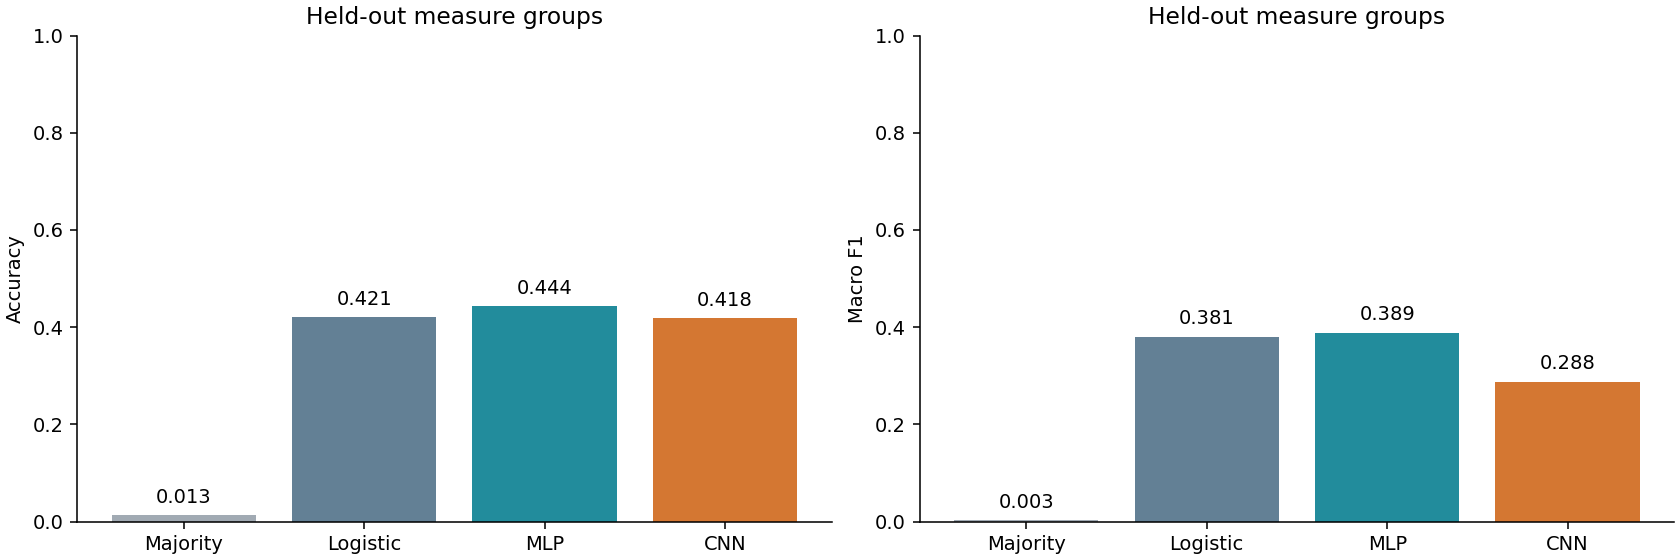

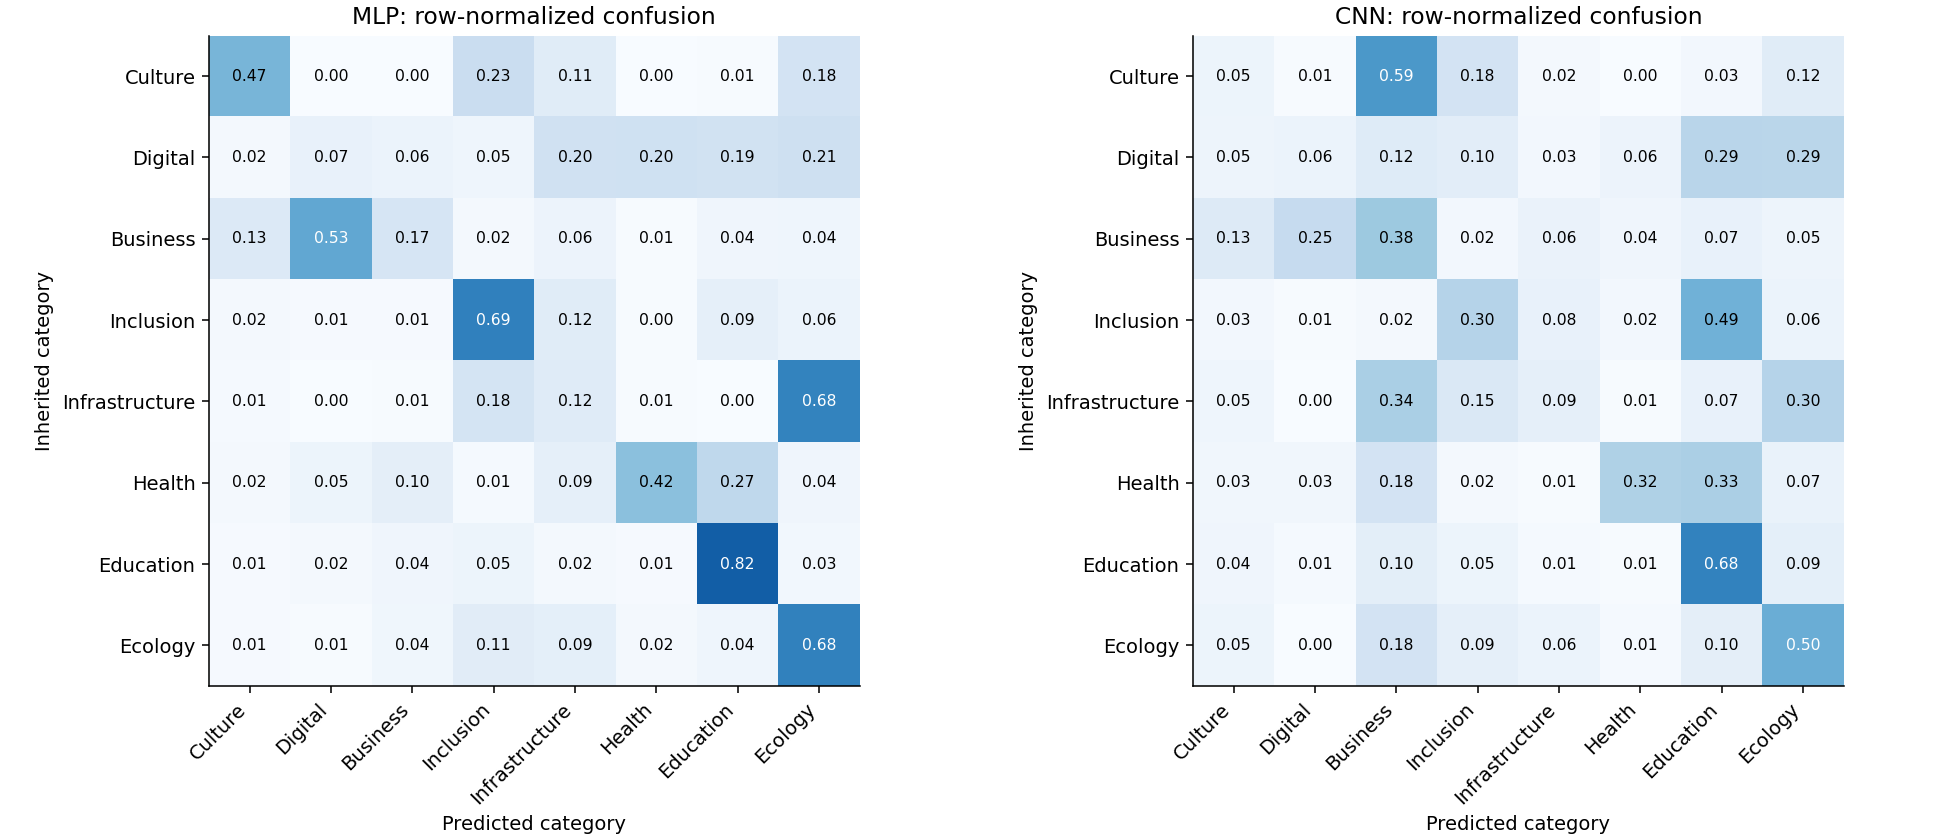

model,CNN,Logistic,MLP,Majority
category,,,,
Cultura e turismo,0.050,0.441,0.413,0.000
Digitalizzazione,0.013,0.005,0.008,0.026
Impresa e lavoro,0.453,0.178,0.270,0.000
Inclusione sociale,0.261,0.458,0.494,0.000
Infrastrutture,0.081,0.151,0.086,0.000
Salute,0.420,0.595,0.556,0.000
"Scuola, università e ricerca",0.664,0.792,0.815,0.000
Transizione ecologica,0.361,0.424,0.469,0.000


In [8]:
display(pd.DataFrame(r['test']).T.round(4))
display(Image(filename=str(A / 'model_comparison.png')))
display(Image(filename=str(A / 'confusion_matrices.png')))
report = pd.read_csv(A / 'classification_reports.csv')
display(report[report.category.isin(r['classes'])].pivot(index='category', columns='model', values='f1-score').round(3))

In [9]:
predictions = pd.read_csv(A / 'test_predictions.csv.gz')
pd.set_option('display.max_colwidth', 140)
for model in ['MLP', 'CNN']:
    print(model, '— three confident errors against inherited labels')
    errors = predictions[predictions[model+'_prediction'] != predictions.label]
    display(errors.sort_values(model+'_confidence', ascending=False)[['titolo', 'label', model+'_prediction', model+'_confidence']].head(3))
print('Paired cluster-bootstrap summaries:')
display(r['bootstrap_mlp_minus_logistic'])
display(r['bootstrap_cnn_minus_mlp'])

MLP — three confident errors against inherited labels


,titolo,label,MLP_prediction,MLP_confidence
18408,Destinazione Scuola: Un sentiero di prevenzione della dispersione scolastica per gli alunni delle scuole secondarie di primo e secondo g...,Inclusione sociale,"Scuola, università e ricerca",0.997929
8337,UNIVERSITA' DEGLI STUDI DI CATANIA DIPARTIMENTO DI SCIENZE BIOMEDICHE E BIOTECNOLOGICHE*VIA SANTA SOFIA 97*PROGETTI DI RICERCA FINANZIAT...,Salute,"Scuola, università e ricerca",0.994186
8485,UNIVERSITÀ DEGLI STUDI DI CAGLIARI - DIPARTIMENTO DI SCIENZE BIOMEDICHE*VIA CITTADELLA UNIVERSITARIA SS 8*SVILUPPO E VALIDAZIONE DI UN P...,Salute,"Scuola, università e ricerca",0.993459


CNN — three confident errors against inherited labels


,titolo,label,CNN_prediction,CNN_confidence
18896,UNIVERSITA' DEGLI STUDI DI ROMA TOR VERGATA*VIA CRACOVIA 50*IL PILASTRO DIAGNOSTICO PER LA DIAGNOSI DELLE INFEZIONI NEL CAMPO ORTOPEDICO...,Salute,"Scuola, università e ricerca",0.999993
8169,UNIVERSITÀ DEGLI STUDI DI SASSARI- DIPARTIMENTO DI SCIENZE BIOMEDICHE*REALIZZAZIONE PROGETTO DAL TITOLO LONGITUDINAL MONITORING FOR THE ...,Salute,"Scuola, università e ricerca",0.999992
10883,UNIVERSITA' DEGLI STUDI DI SASSARI - DIPARTIMENTO DI SCIENZE BIOMEDICHE*VALORE PREDITTIVO CARDIOVASCOLARE DELLA TMAO E DI ALTRI INNOVATI...,Salute,"Scuola, università e ricerca",0.999945


Paired cluster-bootstrap summaries:


{'point_difference': 0.008440293510434682,
 'ci95': [-0.03233769780157055, 0.04221212949777106],
 'one_sided_95_lower': -0.024900676254280617,
 'replicates': 1000,
 'independent_test_groups': 24,
 'caveat': 'Few groups per class; absent classes get F1=0 in a replicate. Interval is exploratory.'}

{'point_difference': -0.10111422528486547,
 'ci95': [-0.17770260149534156, 0.0011915513775782912],
 'one_sided_95_lower': -0.16484455923172575,
 'replicates': 1000,
 'independent_test_groups': 24,
 'caveat': 'Few groups per class; absent classes get F1=0 in a replicate. Interval is exploratory.'}

## 7. Written evaluation

MLP achieved the highest test macro-F1 (0.389). The stronger neural model was MLP (0.389). These values measure agreement with inherited programme themes on unseen measure groups. For the stronger neural model, **Scuola, università e ricerca** was the strongest class (F1 0.815) and **Digitalizzazione** the weakest (F1 0.008). Aggregate accuracy alone would conceal these differences.

What worked: inherited hierarchy labels make a reproducible supervised task possible; strict grouping prevents obvious programme memorization from inflating scores; compact networks train with available CPU resources; validation-driven regularization and checkpoint selection give a measurable comparison. The MLP is efficient because TF–IDF supplies informative lexical features immediately. The CNN can discover local phrases through learned filters, but learning its vocabulary representations from scratch costs more and is sensitive to novel language. Compare measured run times above rather than assuming deeper means better.

What did not work well: fitting training examples did not produce equally strong validation performance. New measures introduce vocabulary and purpose shifts: the CNN test unknown-token rate is 15.7%, versus 3.4% in training. A programme theme can also differ from the literal subject of a title, creating weak-label ambiguity. For example, inspected titles include photovoltaic installations under “Impresa e lavoro” and hotel digitalisation under “Cultura e turismo”. These examples illustrate the distinction; they are not a human annotation study. The proposal's macro-F1 goal of 0.80 was not met by either neural model. The observed neural advantage on this split should be checked across seeds and independently reviewed labels before preferring the more complex pipeline.

The paired group bootstrap (1,000 replicates, 24 test groups) gives MLP minus logistic macro-F1 **+0.0084**, with exploratory 95% interval **[-0.0323, +0.0422]** and one-sided 95% lower bound **-0.0249**. CNN minus MLP is **-0.1011**, interval **[-0.1777, +0.0012]**. Whole groups are resampled jointly for both models; a missing class has F1=0 in that replicate. Both reported intervals span zero, so this experiment does not establish a clear model advantage. Very few groups support some categories, so these intervals are unstable exploratory summaries, not definitive inference. The original hypothesis about independently reviewed project purposes is **not tested**, because no such gold-standard test set exists here.

The main next steps are human review of inherited labels, more independent measure groups per class, and repetition across split/initialization seeds. `label_review_sample.csv` provides examples with blank review fields; it is not claimed to be annotated. Deployment would also need probability calibration and an abstention option for unknown themes. No conclusion about funding fairness, regional performance, or future snapshots follows from these classification scores.



## 8. Reload a trained model

Use the saved preprocessing and the selected checkpoint; never refit vocabulary at inference. These are uncalibrated exploratory predictions.

In [10]:
from predict import classify
display(classify('Riqualificazione energetica della scuola primaria comunale', 'MLP'))
display(classify('Realizzazione di un nuovo ospedale di comunità', 'CNN'))

{'title': 'Riqualificazione energetica della scuola primaria comunale',
 'cleaned_title': 'riqualificazione energetica della scuola primaria comunale',
 'model': 'mlp_regularized',
 'top_categories': [{'category': 'Inclusione sociale',
   'probability': 0.47612184286117554},
  {'category': 'Infrastrutture', 'probability': 0.4367870092391968},
  {'category': 'Cultura e turismo', 'probability': 0.05110533908009529}],
 'note': 'Uncalibrated model probabilities; predicts inherited programme themes, not verified project purpose.'}

{'title': 'Realizzazione di un nuovo ospedale di comunità',
 'cleaned_title': 'realizzazione di un nuovo ospedale di comunità',
 'model': 'cnn_plain',
 'top_categories': [{'category': 'Salute', 'probability': 0.9997872710227966},
  {'category': 'Impresa e lavoro', 'probability': 0.00019789990619756281},
  {'category': 'Infrastrutture', 'probability': 1.3373673937167041e-05}],
 'note': 'Uncalibrated model probabilities; predicts inherited programme themes, not verified project purpose.'}

## Deliverables and validation

See `REPORT.md` and `README.md`. Saved artifacts include complete preprocessing audits, source hashes, manifests, four neural checkpoints, baseline model, per-epoch logs, predictions, plots, and per-class metrics. Run `python -m unittest discover -s tests -v` for cleaning, padding, and split-integrity checks. The label-review CSV is an unannotated template, not gold-standard validation.